# Road Inventory EDA and Feature Quality

**Study:** the 2022 MassDOT inventory in Boston, Brookline, Cambridge, Dedham, Everett,
Milton, Needham, Newton, Quincy, Revere, Somerville, Watertown and Winthrop.

One row is one original inventory line record, not a complete street. This notebook examines
road attributes without crash labels or imagery. It cannot estimate crash risk, measure predictive
performance, or establish which features improve a crash model.

This is a new public-service extract. It builds on Molly's acquisition and conservative audit,
and uses the same 13-municipality list as Chun's current geospatial notebook. It does not reproduce
their original snapshots or define the final crash/image modeling cohort. No road is selected by
crash outcome. Source data and identifiers remain intact.

**Run:** install `requirements-eda.txt`, run `python scripts/download_roads.py` once, then run this
notebook from the repository root or `notebooks/`. With a complete cache, the notebook runs offline.

Questions: How does the road mix vary across municipalities? Where are attributes missing?
How old and well-documented are AADT values? How do complete-case rules change the sample?

In [1]:
from pathlib import Path
import os
import json
import hashlib
import base64
import html
import numpy as np
import pandas as pd

cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "reports" / "tables"
FIGURES = ROOT / "figures"
REPORTS = ROOT / "reports"
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import matplotlib.pyplot as plt
from shapely.geometry import MultiLineString
from IPython.display import display, Markdown

for folder in [PROCESSED, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRAY = "#286a95", "#b66b31", "#81878c"

def save_table(frame, name):
    frame.to_csv(TABLES / f"{name}.csv", index=True)

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

manifest = json.loads((RAW / "manifest.json").read_text())
assert manifest["status"] == "complete", "Finish the download before analysis."
for relative, digest in manifest["sha256"].items():
    assert hashlib.sha256((RAW / relative).read_bytes()).hexdigest() == digest, relative
schema = json.loads((RAW / "road_layer.json").read_text())
features = []
for path in sorted((RAW / "batches").glob("*.json")):
    features.extend(json.loads(path.read_text())["features"])
roads = pd.DataFrame(f["attributes"] for f in features)
assert sorted(roads.OBJECTID.tolist()) == manifest["requested_ids"]
assert len(roads) == manifest["downloaded_records"]
assert roads.OBJECTID.is_unique and roads.GlobalID.notna().all() and roads.GlobalID.is_unique
domains = {field["name"]: {item["code"]: item["name"] for item in
           (field.get("domain") or {}).get("codedValues", [])} for field in schema["fields"]}
display(Markdown(f"**Verified snapshot:** {len(roads):,} original road records. "
                 f"Inventory: {manifest['inventory_year']}. Retrieved: {manifest['completed_at_utc']}."))

**Verified snapshot:** 55,143 original road records. Inventory: 2022. Retrieved: 2026-11-24T17:06:35.694706+00:00.

## 1. Identifiers, units and a provisional road screen

`segment_id` preserves `GlobalID` for Molly/Bryan. `segment_id_objectid` provides Chun's
`2022:OBJECTID` form. The crosswalk is valid within this extract; it does not prove that another
snapshot has identical records. Original `Rd_Seg_ID` values may repeat and are not deduplication keys.

The layer uses EPSG:26986, so planar geometry lengths are in meters. Source `Length` is in miles.
Surface and sidewalk widths are in feet. Posted speeds are treated as mph, consistent with the
MassDOT/MAPC documentation linked below. `Opp_Lanes = 0` can be meaningful and is preserved.

Use the **2022 layer's domains** for categories. The currently available MassDOT dictionary is
labelled **2024**; use it for shared field definitions and units, not to overwrite 2022 codes.

Retain all source rows, then flag invalid/empty geometry, zero length and bicycle/pedestrian-only
facilities. The remaining set is a provisional motor-road screen. Unknown facility/class values
remain visible. We do not deduplicate linework or claim that summed segment length is unique
physical centerline mileage.

In [2]:
roads["segment_id"] = roads.GlobalID.astype("string")
roads["segment_id_objectid"] = "2022:" + roads.OBJECTID.astype("Int64").astype("string")
roads["municipality"] = roads.City.map(domains["City"])
roads["road_class"] = roads.F_Class.map(domains["F_Class"]).fillna("Unknown / missing")
roads["facility_name"] = roads.Facility.map(domains["Facility"]).fillna("Unknown / missing")
class_short = {0: "0 Local", 1: "1 Interstate", 2: "2 Principal arterial",
               3: "3 Minor/principal arterial", 5: "5 Arterial/collector", 6: "6 Collector"}
roads["class_label"] = roads.F_Class.map(class_short).fillna("Unknown / missing")
assert set(roads.municipality) == set(manifest["towns"])

def inspect_geometry(feature):
    paths = (feature.get("geometry") or {}).get("paths")
    if not paths:
        return "missing_or_unsupported", np.nan
    try:
        xy = [np.asarray(path, dtype=float)[:, :2] for path in paths]
        if any(len(path) < 2 or not np.isfinite(path).all() for path in xy):
            return "invalid_coordinates", np.nan
        line = MultiLineString(xy)
        if line.is_empty or not line.is_valid:
            return "invalid_geometry", float(line.length)
        return ("zero_length" if line.length <= 0 else "valid"), float(line.length)
    except (ValueError, TypeError, IndexError):
        return "invalid_geometry", np.nan

geometry = pd.DataFrame([inspect_geometry(f) for f in features],
                        columns=["geometry_status", "geometry_length_m"], index=roads.index)
roads = pd.concat([roads, geometry], axis=1)
roads["screen_status"] = np.select(
    [roads.geometry_status.ne("valid"), roads.Facility.eq(12)],
    ["Geometry review", "Bicycle/pedestrian facility"], default="Retained for road EDA")
screen = roads.screen_status.value_counts().rename_axis("screen_status").to_frame("segments")
screen["share_of_source"] = screen.segments / len(roads)
save_table(screen, "screening_counts")
roads[["OBJECTID", "GlobalID", "Rd_Seg_ID", "segment_id", "segment_id_objectid", "municipality"]].to_csv(
    PROCESSED / "segment_id_crosswalk.csv", index=False)
display(screen)

domain_checks = []
for field in ["F_Class", "F_F_Class", "Facility", "AADT_Deriv", "Operation", "Control"]:
    domain_checks.append({"field": field, "missing": int(roads[field].isna().sum()),
        "nonmissing_unmapped": int((roads[field].notna() & ~roads[field].isin(domains[field])).sum())})
domain_checks = pd.DataFrame(domain_checks).set_index("field")
save_table(domain_checks, "category_domain_checks")
display(domain_checks)

roads["source_length_m"] = pd.to_numeric(roads.Length, errors="coerce") * 1609.344
length_ratio = roads.geometry_length_m.div(roads.source_length_m.where(roads.source_length_m.gt(0)))
length_check = pd.Series({"source_records": len(roads),
    "missing_or_repeated_GlobalID": int(roads.GlobalID.isna().sum() + roads.GlobalID.duplicated().sum()),
    "repeated_Rd_Seg_ID_rows": int(roads.Rd_Seg_ID.dropna().duplicated().sum()),
    "median_geometry_to_source_length_ratio": length_ratio.median(),
    "length_ratio_outside_0.8_to_1.2_review_only": int((length_ratio.notna() & ~length_ratio.between(.8, 1.2)).sum())})
save_table(length_check.to_frame("value"), "identifier_and_length_checks")
display(length_check)

,segments,share_of_source
screen_status,,
Retained for road EDA,54647,0.991005
Bicycle/pedestrian facility,426,0.007725
Geometry review,70,0.001269


,missing,nonmissing_unmapped
field,,
F_Class,699,0
F_F_Class,699,0
Facility,7124,0
AADT_Deriv,34238,0
Operation,7931,50
Control,992,0


source_records                                 55143.000000
missing_or_repeated_GlobalID                       0.000000
repeated_Rd_Seg_ID_rows                         5888.000000
median_geometry_to_source_length_ratio             1.000002
length_ratio_outside_0.8_to_1.2_review_only      578.000000
dtype: float64

## 2. Attribute preparation without imputation

Preserve source columns. Positive AADT is **reported traffic volume**, not necessarily an actual
count: the derivation domain distinguishes actual, estimated, grown and default values.
`AADT = 1154` with a missing derivation is a **suspected default**, based on the team's observation.
It is not independently established as a source coding rule. Keep it in the reported-value analysis
and compare an explicit sensitivity scenario excluding it. Derivation code 13 is explicitly a
default in the source metadata.

AADT years must be integers from 1900 through 2022 to count as known pre-outcome years.
Age is measured relative to the **2022 inventory**, not the 2026 download. Nonpositive width/lane
values are unavailable for these summaries. Posted speed 99 is flagged and omitted from the
working speed summary as a suspected special value. These choices do not alter the raw fields.
No statistical outlier is automatically deleted, and no missing value is imputed.

In [3]:
numeric_fields = ["AADT", "AADT_Year", "AADT_Deriv", "Surface_Wd", "Speed_Lim",
                  "Num_Lanes", "Opp_Lanes", "Lt_Sidewlk", "Rt_Sidewlk"]
for name in numeric_fields:
    roads[name + "_numeric"] = pd.to_numeric(roads[name], errors="coerce")
roads["aadt_reported"] = roads.AADT_numeric.where(roads.AADT_numeric.gt(0))
roads["aadt_suspected_default_1154"] = roads.AADT_numeric.eq(1154) & roads.AADT_Deriv_numeric.isna()
roads["aadt_explicit_default_code"] = roads.AADT_Deriv_numeric.eq(13)
roads["aadt_screened_sensitivity"] = roads.aadt_reported.mask(
    roads.aadt_suspected_default_1154 | roads.aadt_explicit_default_code)
year = roads.AADT_Year_numeric
roads["aadt_year_pre2023"] = year.where(year.between(1900, 2022) & year.eq(np.floor(year)))
roads["aadt_age_at_inventory"] = 2022 - roads.aadt_year_pre2023
roads["aadt_derivation"] = roads.AADT_Deriv.map(domains["AADT_Deriv"]).fillna("Unknown / missing")
roads["road_width_ft"] = roads.Surface_Wd_numeric.where(roads.Surface_Wd_numeric.gt(0))
roads["posted_speed_mph"] = roads.Speed_Lim_numeric.where(
    roads.Speed_Lim_numeric.gt(0) & roads.Speed_Lim_numeric.ne(99))
roads["travel_lanes"] = roads.Num_Lanes_numeric.where(roads.Num_Lanes_numeric.gt(0))

df = roads.loc[roads.screen_status.eq("Retained for road EDA")].copy()
assert len(df) + int(roads.screen_status.ne("Retained for road EDA").sum()) == len(roads)
df.to_csv(PROCESSED / "roads_eda.csv", index=False)
roads.loc[roads.screen_status.ne("Retained for road EDA")].to_csv(
    PROCESSED / "roads_screened_out.csv", index=False)
original = pd.DataFrame(f["attributes"] for f in features)
assert roads[manifest["fields"]].equals(original[manifest["fields"]]), "Source values changed."

feature_map = pd.DataFrame([
    ("GlobalID", "segment_id", "Identifier", "Preserved for joins"),
    ("Geometry", "geometry_length_m", "meters", "Valid positive line length"),
    ("AADT", "aadt_reported", "vehicles/day", "Positive reported values, including flagged candidates"),
    ("AADT, AADT_Deriv", "aadt_screened_sensitivity", "vehicles/day", "Exclude suspected 1154 and explicit default codes, sensitivity only"),
    ("AADT_Year", "aadt_year_pre2023", "year", "Integer 1900 through 2022"),
    ("Surface_Wd", "road_width_ft", "feet", "Positive values"),
    ("Speed_Lim", "posted_speed_mph", "mph", "Positive values except suspected special code 99"),
    ("Num_Lanes", "travel_lanes", "lanes", "Positive values; opposing lanes remain separate"),
], columns=["source", "analysis_field", "unit", "rule"]).set_index("analysis_field")
save_table(feature_map, "feature_definitions")
display(feature_map)

,source,unit,rule
analysis_field,,,
segment_id,GlobalID,Identifier,Preserved for joins
geometry_length_m,Geometry,meters,Valid positive line length
aadt_reported,AADT,vehicles/day,"Positive reported values, including flagged ca..."
aadt_screened_sensitivity,"AADT, AADT_Deriv",vehicles/day,Exclude suspected 1154 and explicit default co...
aadt_year_pre2023,AADT_Year,year,Integer 1900 through 2022
road_width_ft,Surface_Wd,feet,Positive values
posted_speed_mph,Speed_Lim,mph,Positive values except suspected special code 99
travel_lanes,Num_Lanes,lanes,Positive values; opposing lanes remain separate


## 3. Road composition across municipalities

All figures below use the provisional road screen, including unknown facility/class records.
Segment counts depend on how the inventory divides roads. Length is the sum of inventoried line
records, not a deduplicated centerline network. The stacked chart uses **within-municipality
percentages**, so it compares composition rather than city size.

,segments,inventoried_length_km,median_segment_m,reported_aadt_share,speed_available_share,segment_share
municipality,,,,,,
Boston,22346,2122.261,69.154,0.823,0.257,0.409
Brookline,2207,218.033,73.523,0.832,0.420,0.040
Cambridge,3627,290.825,65.124,0.872,0.294,0.066
Dedham,2172,249.091,78.585,0.814,0.249,0.040
Everett,1747,139.833,62.554,0.746,0.243,0.032
Milton,2199,257.655,79.277,0.825,0.317,0.040
Needham,2171,277.892,92.258,0.875,0.238,0.040
Newton,6066,598.381,79.152,0.866,0.217,0.111
Quincy,4426,446.716,76.594,0.856,0.226,0.081


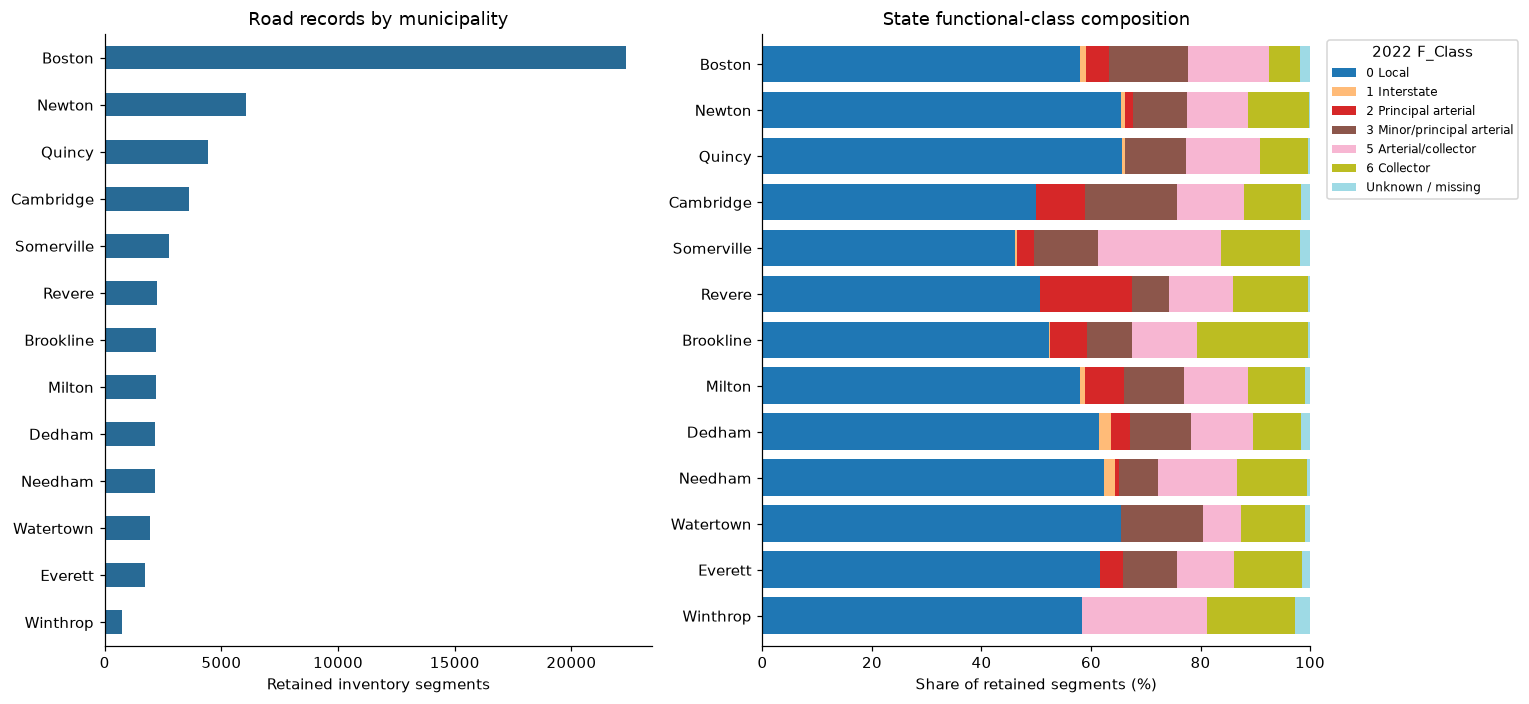

In [4]:
municipalities = df.groupby("municipality").agg(
    segments=("segment_id", "size"), inventoried_length_km=("geometry_length_m", lambda s: s.sum()/1000),
    median_segment_m=("geometry_length_m", "median"),
    reported_aadt_share=("aadt_reported", lambda s: s.notna().mean()),
    speed_available_share=("posted_speed_mph", lambda s: s.notna().mean()))
municipalities["segment_share"] = municipalities.segments / len(df)
save_table(municipalities, "municipality_profile")
display(municipalities.round(3))

class_mix = pd.crosstab(df.municipality, df.class_label)
class_share = class_mix.div(class_mix.sum(axis=1), axis=0)
save_table(class_mix, "road_class_counts_by_municipality")
save_table(class_share, "road_class_shares_by_municipality")
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
order = municipalities.segments.sort_values().index
municipalities.loc[order, "segments"].plot.barh(ax=axes[0], color=BLUE)
axes[0].set(title="Road records by municipality", xlabel="Retained inventory segments", ylabel="")
class_share.loc[order].mul(100).plot.barh(stacked=True, ax=axes[1], colormap="tab20", width=.8)
axes[1].set(title="State functional-class composition", xlabel="Share of retained segments (%)", ylabel="", xlim=(0,100))
axes[1].legend(title="2022 F_Class", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
save_figure(fig, "01_road_composition")

## 4. Feature distributions and missingness

Histograms use available values only; their titles state the number included. Logarithmic axes
make long right tails visible without removing large values. The missingness heatmaps use every
retained segment in each row group as the denominator. Blank/unknown categories are not treated
as valid measurements simply because a string is present.

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_share
geometry_length_m,54647.0,96.42,120.64,0.0,0.03,38.4,71.79,120.16,484.01,7371.17,0.00
aadt_reported,45851.0,9011.43,17664.20,10.0,1154.00,1154.0,1154.00,11160.00,83587.50,220885.00,0.16
posted_speed_mph,14476.0,30.69,6.39,10.0,20.00,30.0,30.00,30.00,55.00,55.00,0.74
road_width_ft,46044.0,27.78,8.48,6.0,10.00,24.0,26.00,32.00,55.00,84.00,0.16
travel_lanes,49245.0,2.02,0.49,1.0,1.00,2.0,2.00,2.00,4.00,5.00,0.10


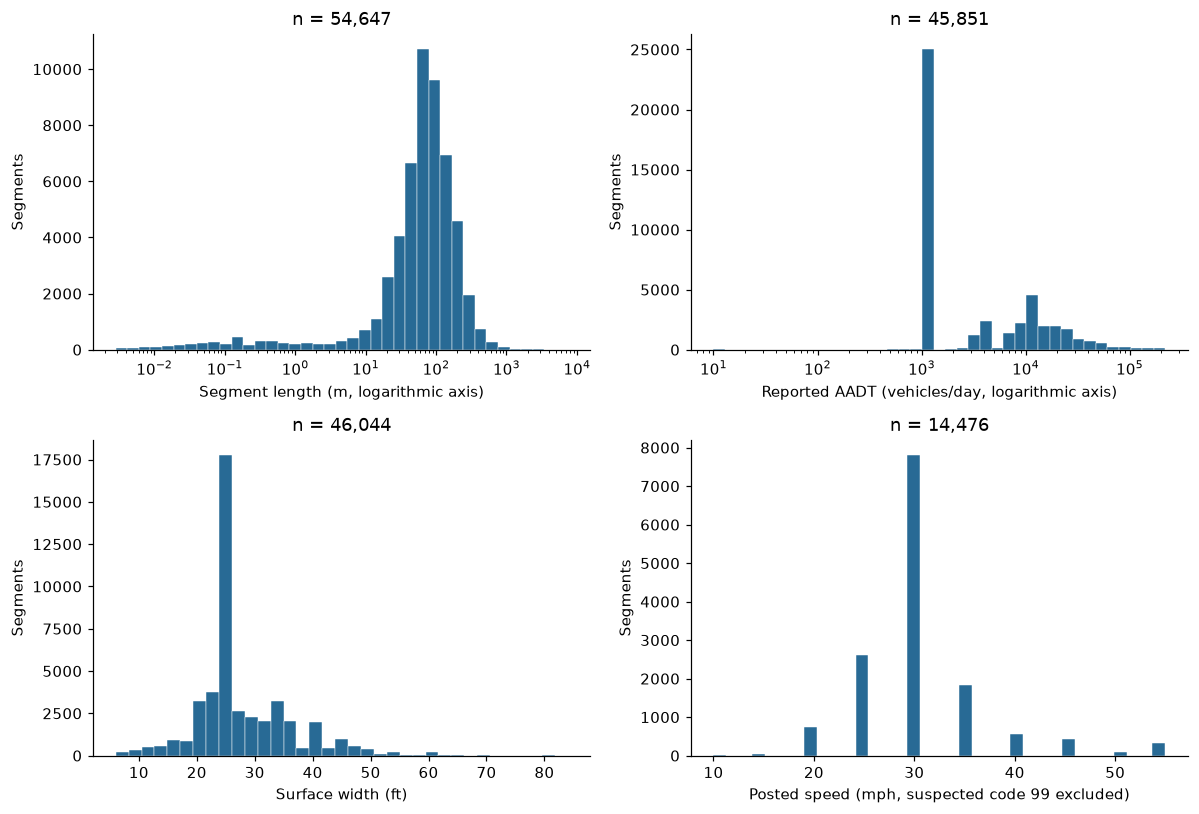

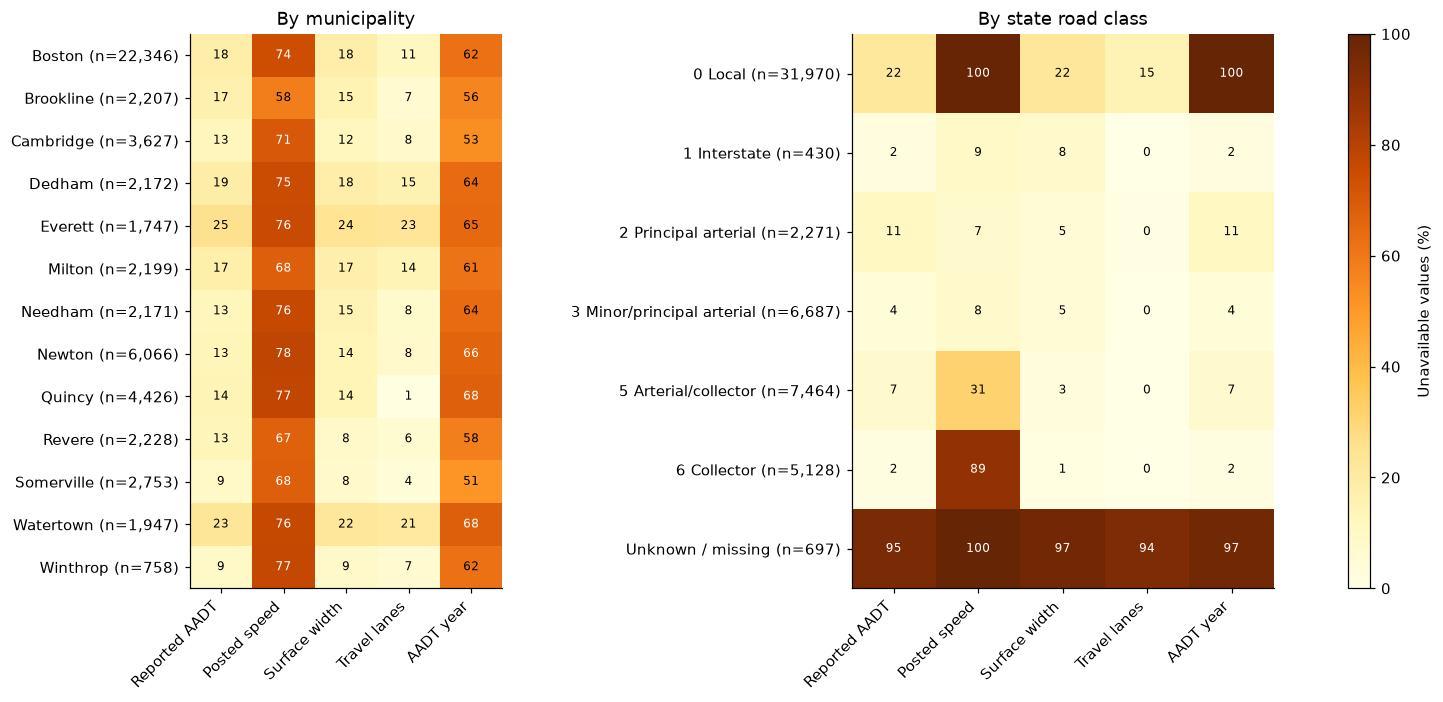

In [5]:
analysis_fields = ["aadt_reported", "posted_speed_mph", "road_width_ft", "travel_lanes"]
names = {"aadt_reported": "Reported AADT", "posted_speed_mph": "Posted speed",
         "road_width_ft": "Surface width", "travel_lanes": "Travel lanes",
         "aadt_year_pre2023": "AADT year"}
summary_fields = ["geometry_length_m"] + analysis_fields
summary = df[summary_fields].describe(percentiles=[.01,.25,.5,.75,.99]).T
summary["missing_share"] = df[summary_fields].isna().mean()
save_table(summary, "numeric_feature_summary")
display(summary.round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, field, label, log in zip(axes.flat,
    ["geometry_length_m", "aadt_reported", "road_width_ft", "posted_speed_mph"],
    ["Segment length (m, logarithmic axis)", "Reported AADT (vehicles/day, logarithmic axis)",
     "Surface width (ft)", "Posted speed (mph, suspected code 99 excluded)"], [True,True,False,False]):
    values = df[field].dropna()
    bins = np.geomspace(values.min(), values.max(), 40) if log else 35
    ax.hist(values, bins=bins, color=BLUE, edgecolor="white", linewidth=.3)
    if log: ax.set_xscale("log")
    ax.set(xlabel=label, ylabel="Segments", title=f"n = {len(values):,}")
fig.tight_layout()
save_figure(fig, "02_feature_distributions")

missing_fields = analysis_fields + ["aadt_year_pre2023"]
missing = df[missing_fields].isna()
quality = pd.DataFrame({"available": (~missing).sum(), "unavailable": missing.sum(),
                        "unavailable_share": missing.mean()})
save_table(quality, "feature_availability")
raw_quality = pd.DataFrame({"missing_or_blank": original.apply(lambda s: (s.isna() | s.astype("string").str.strip().eq("")).sum()),
                            "source_rows": len(original)})
save_table(raw_quality, "raw_field_completeness")
missing_town = missing.groupby(df.municipality).mean().mul(100)
missing_class = missing.groupby(df.class_label).mean().mul(100)
save_table(missing_town, "missing_percent_by_municipality")
save_table(missing_class, "missing_percent_by_road_class")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 7), gridspec_kw={"width_ratios": [1,1.35]})
for ax, matrix, group, title in [(axes[0], missing_town, df.municipality, "By municipality"),
                                (axes[1], missing_class, df.class_label, "By state road class")]:
    im = ax.imshow(matrix, vmin=0, vmax=100, cmap="YlOrBr", aspect="auto")
    ax.set_xticks(range(len(missing_fields)), [names[c] for c in missing_fields], rotation=45, ha="right")
    counts = group.value_counts()
    ax.set_yticks(range(len(matrix)), [f"{name} (n={counts[name]:,})" for name in matrix.index])
    ax.set_title(title)
    for i in range(len(matrix)):
        for j in range(len(missing_fields)):
            value = matrix.iloc[i,j]
            ax.text(j,i,f"{value:.0f}",ha="center",va="center",fontsize=8,color="white" if value>65 else "black")
fig.subplots_adjust(left=.15, right=.88, bottom=.2, top=.92, wspace=.95)
cax = fig.add_axes([.93, .2, .015, .72])
fig.colorbar(im, cax=cax, label="Unavailable values (%)")
save_figure(fig, "03_missingness_by_group")

## 5. AADT provenance and measurement age

Compare three explicit definitions: all positive reported AADT, positive AADT with a known
pre-2023 year, and the sensitivity version excluding suspected/default entries. A nonmissing
AADT is not proof of a direct traffic count. A missing year cannot be assigned age zero.
The 1154 flag is a hypothesis to discuss with the team, not an official lookup code.

,available_segments,share_of_retained,median_aadt
definition,,,
Positive reported AADT,45851,0.839,1154.0
Reported AADT with known pre-2023 year,20858,0.382,11160.0
AADT excluding suspected/explicit defaults,20859,0.382,11160.0


,segments
"AADT 1154, missing derivation (suspected)",24992
AADT derivation 13 (explicit default),0
Positive AADT without known pre-2023 year,24993
"AADT derivation 1 (actual), positive AADT",348
Posted speed 99 (suspected special value),7371


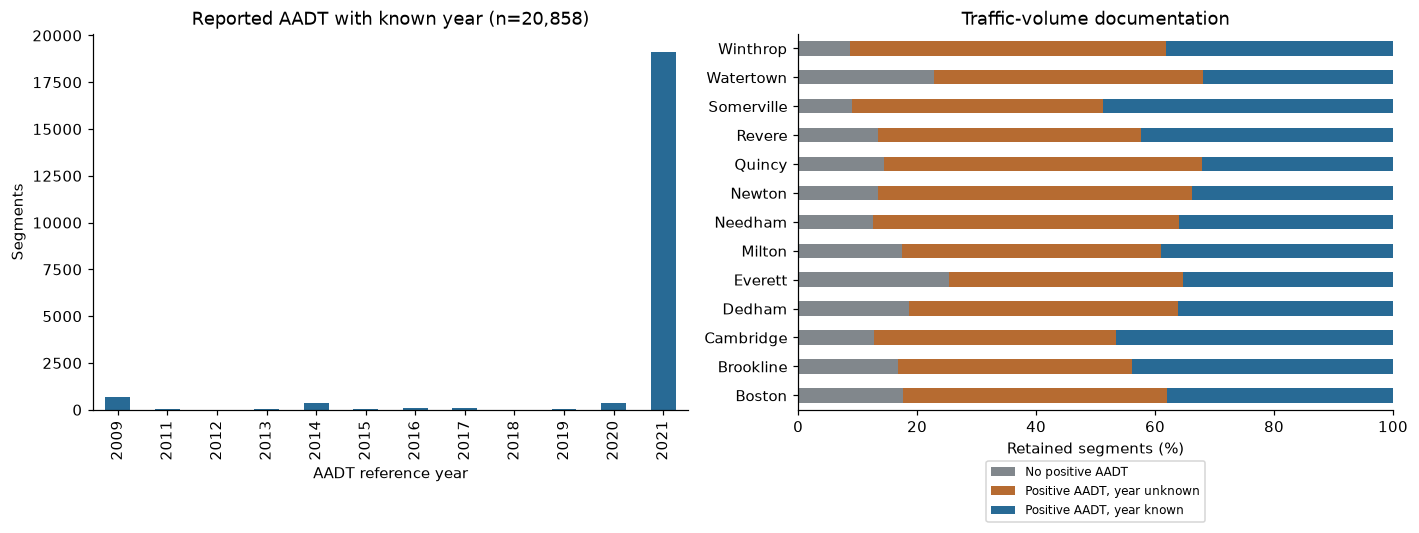

In [6]:
aadt_versions = {
    "Positive reported AADT": df.aadt_reported,
    "Reported AADT with known pre-2023 year": df.aadt_reported.where(df.aadt_year_pre2023.notna()),
    "AADT excluding suspected/explicit defaults": df.aadt_screened_sensitivity,
}
aadt_summary = pd.DataFrame([{"definition": name, "available_segments": int(s.notna().sum()),
    "share_of_retained": s.notna().mean(), "median_aadt": s.median()}
    for name,s in aadt_versions.items()]).set_index("definition")
save_table(aadt_summary, "aadt_definition_sensitivity")
display(aadt_summary.round(3))
aadt_flags = pd.Series({
    "AADT 1154, missing derivation (suspected)": int(df.aadt_suspected_default_1154.sum()),
    "AADT derivation 13 (explicit default)": int(df.aadt_explicit_default_code.sum()),
    "Positive AADT without known pre-2023 year": int((df.aadt_reported.notna() & df.aadt_year_pre2023.isna()).sum()),
    "AADT derivation 1 (actual), positive AADT": int((df.AADT_Deriv_numeric.eq(1) & df.aadt_reported.notna()).sum()),
    "Posted speed 99 (suspected special value)": int(df.Speed_Lim_numeric.eq(99).sum()),
}).to_frame("segments")
save_table(aadt_flags, "special_value_flags")
derivation = df.loc[df.aadt_reported.notna(), "aadt_derivation"].value_counts().to_frame("segments")
save_table(derivation, "aadt_derivation_counts")
display(aadt_flags)

fig, axes = plt.subplots(1,2,figsize=(13,5))
known = df.loc[df.aadt_reported.notna() & df.aadt_year_pre2023.notna(), "aadt_year_pre2023"].astype(int)
known.value_counts().sort_index().plot.bar(ax=axes[0], color=BLUE)
axes[0].set(title=f"Reported AADT with known year (n={len(known):,})", xlabel="AADT reference year", ylabel="Segments")
categories = ["No positive AADT", "Positive AADT, year unknown", "Positive AADT, year known"]
df["aadt_documentation"] = np.select(
    [df.aadt_reported.isna(), df.aadt_year_pre2023.isna()], categories[:2], default=categories[2])
documentation = pd.crosstab(df.municipality, df.aadt_documentation).reindex(columns=categories, fill_value=0)
documentation.div(documentation.sum(axis=1),axis=0).mul(100).plot.barh(
    stacked=True, color=[GRAY, ORANGE, BLUE], ax=axes[1])
axes[1].set(title="Traffic-volume documentation", xlabel="Retained segments (%)", ylabel="", xlim=(0,100))
axes[1].legend(loc="upper center",bbox_to_anchor=(.5,-.12),fontsize=8)
fig.tight_layout()
save_figure(fig, "04_aadt_provenance")

## 6. Relationships between predictors

Spearman correlations describe monotonic relationships between available road measurements.
Each pair uses its own nonmissing records, with at least 30 pairs. Compare all retained roads
with local roads to show how road-class composition affects associations. Missing-value patterns
can also affect these comparisons. Correlations do not establish predictive value for crashes,
causal effects, or whether two features are interchangeable in a future model.

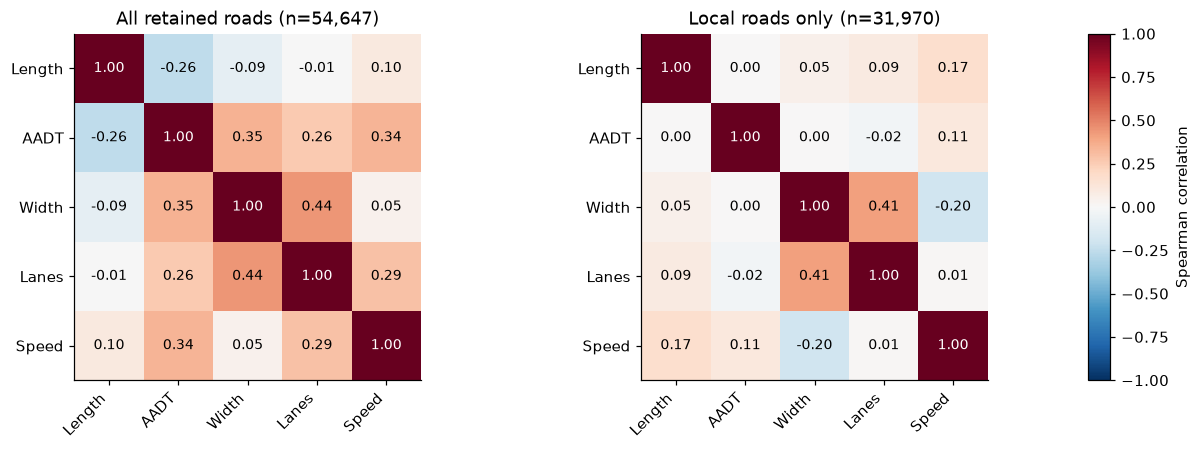

In [7]:
corr_fields = ["geometry_length_m", "aadt_reported", "road_width_ft", "travel_lanes", "posted_speed_mph"]
corr_labels = ["Length", "AADT", "Width", "Lanes", "Speed"]
fig, axes = plt.subplots(1,2,figsize=(11.5,4.5))
for ax, part, label, filename in [(axes[0], df, "All retained roads", "all"),
                                (axes[1], df.loc[df.F_Class.eq(0)], "Local roads only", "local")]:
    matrix = part[corr_fields].corr(method="spearman", min_periods=30)
    present = part[corr_fields].notna().astype(int)
    pairs = present.T.dot(present)
    save_table(matrix, f"spearman_{filename}")
    save_table(pairs, f"correlation_pair_counts_{filename}")
    im = ax.imshow(matrix, vmin=-1,vmax=1,cmap="RdBu_r")
    ax.set_xticks(range(5),corr_labels,rotation=45,ha="right")
    ax.set_yticks(range(5),corr_labels)
    ax.set_title(f"{label} (n={len(part):,})")
    for i in range(5):
        for j in range(5):
            value = matrix.iloc[i,j]
            ax.text(j,i,f"{value:.2f}" if pd.notna(value) else "n/a",ha="center",va="center",
                    color="white" if abs(value)>.65 else "black",fontsize=9)
fig.subplots_adjust(left=.08,right=.86,bottom=.2,top=.9,wspace=.35)
cax = fig.add_axes([.91,.2,.018,.7])
fig.colorbar(im,cax=cax,label="Spearman correlation")
save_figure(fig, "05_predictor_relationships")

## 7. Complete-case filtering changes the population

These are **alternative descriptive filters**, not sequential cleaning steps or recommendations
to drop records. The four-feature requirement uses reported positive AADT, usable posted speed,
surface width and travel lanes. The stricter sensitivity also requires a known AADT year and
excludes suspected/explicit AADT defaults. Unknown categories remain explicit.

For a later model, training-fitted imputation may retain more roads. Decide preprocessing using
training data, then preserve the agreed geographic test assignment. These filters must not be
chosen to improve test-set performance.

,retained,excluded,retained_share
rule,,,
All screened roads,54647,0,1.000
Reported AADT available,45851,8796,0.839
AADT and pre-2023 year available,20858,33789,0.382
Posted speed available,14476,40171,0.265
All four features available,13348,41299,0.244
"Four features, AADT year and default screen",13221,41426,0.242


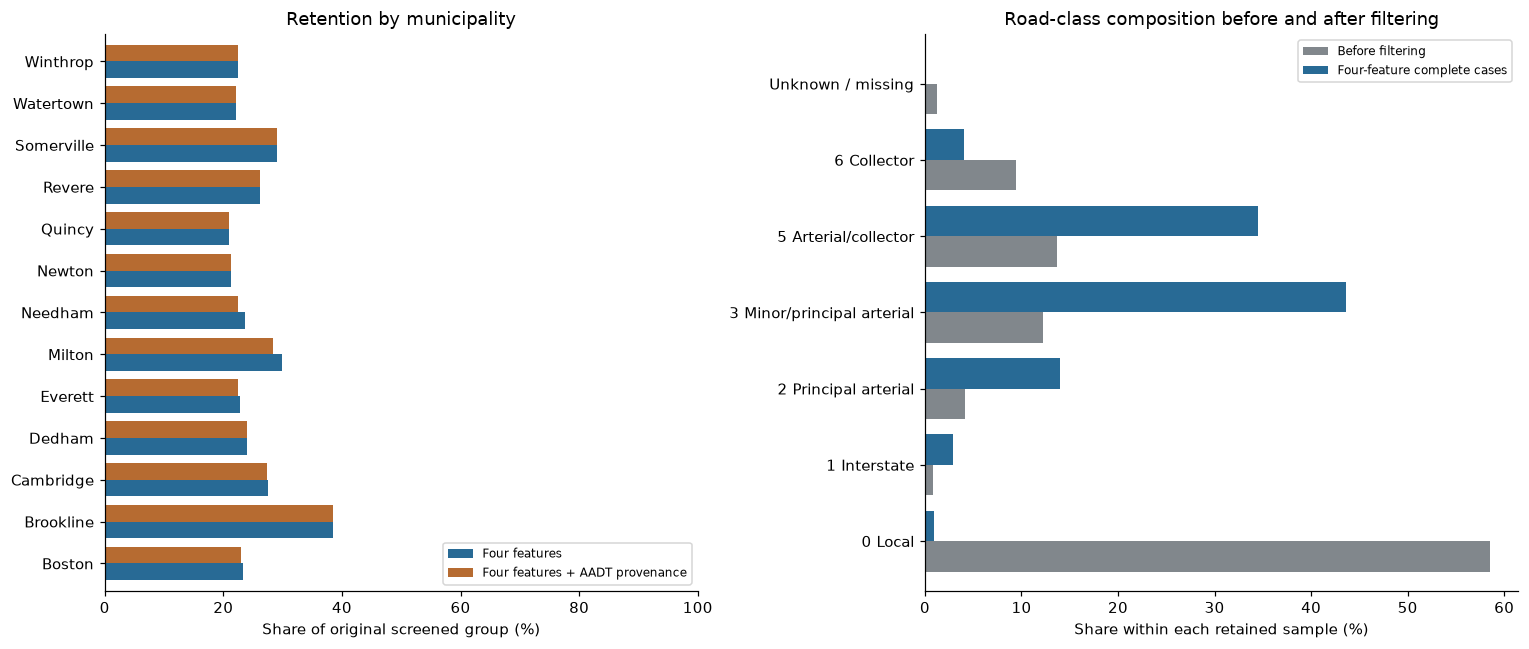

In [8]:
complete = df[analysis_fields].notna().all(axis=1)
filters = {
    "All screened roads": pd.Series(True, index=df.index),
    "Reported AADT available": df.aadt_reported.notna(),
    "AADT and pre-2023 year available": df.aadt_reported.notna() & df.aadt_year_pre2023.notna(),
    "Posted speed available": df.posted_speed_mph.notna(),
    "All four features available": complete,
    "Four features, AADT year and default screen": complete & df.aadt_year_pre2023.notna() & df.aadt_screened_sensitivity.notna(),
}
retention = pd.DataFrame([{"rule": name, "retained": int(mask.sum()), "excluded": int((~mask).sum()),
                           "retained_share": mask.mean()} for name,mask in filters.items()]).set_index("rule")
save_table(retention, "filter_retention")
display(retention.round(3))
by_town = pd.DataFrame({name:mask.groupby(df.municipality).mean() for name,mask in filters.items()})
save_table(by_town, "filter_retention_by_municipality")
filter_class_counts = pd.DataFrame({name:df.loc[mask,"class_label"].value_counts() for name,mask in filters.items()}).fillna(0).astype(int)
filter_class_shares = filter_class_counts.div(filter_class_counts.sum(axis=0),axis=1)
save_table(filter_class_counts, "filter_road_class_counts")
save_table(filter_class_shares, "filter_road_class_shares")
assert (retention.retained + retention.excluded).eq(len(df)).all()
assert (by_town.ge(0) & by_town.le(1)).all().all()
assert filter_class_counts.sum().eq(retention.retained).all()

fig, axes = plt.subplots(1,2,figsize=(14,6))
by_town[["All four features available", "Four features, AADT year and default screen"]].mul(100).plot.barh(
    ax=axes[0],color=[BLUE,ORANGE],width=.8)
axes[0].set(title="Retention by municipality",xlabel="Share of original screened group (%)",ylabel="",xlim=(0,100))
axes[0].legend(["Four features", "Four features + AADT provenance"],loc="lower right",fontsize=8)
chosen = ["All screened roads", "All four features available"]
filter_class_shares[chosen].mul(100).plot.barh(ax=axes[1],color=[GRAY,BLUE],width=.8)
axes[1].set(title="Road-class composition before and after filtering",xlabel="Share within each retained sample (%)",ylabel="")
axes[1].legend(["Before filtering", "Four-feature complete cases"],fontsize=8)
fig.tight_layout()
save_figure(fig, "06_filtering_effects")

## 8. Findings and handoff

The following statements are computed from this snapshot. They are road-data findings, not model
results. Differences from earlier saved notebooks can reflect the extraction date, screen or
definition, and must be reconciled using identifiers before joins.

In [9]:
n = len(df)
speed_low = missing_town.posted_speed_mph.idxmax()
speed_high = missing_town.posted_speed_mph.idxmin()
positive_aadt = df.aadt_reported.notna()
unknown_year = positive_aadt & df.aadt_year_pre2023.isna()
local_before = df.F_Class.eq(0).mean()
local_after = df.loc[complete,"F_Class"].eq(0).mean()
median_age = df.loc[positive_aadt,"aadt_age_at_inventory"].median()
findings = [
    f"The extract contains {len(roads):,} original records. The provisional geometry/facility screen retains {n:,} ({n/len(roads):.1%}) across {df.municipality.nunique()} municipalities.",
    f"Usable posted speed is unavailable for {df.posted_speed_mph.isna().mean():.1%} of screened roads. Unavailability ranges from {missing_town.loc[speed_high,'posted_speed_mph']:.1f}% in {speed_high} to {missing_town.loc[speed_low,'posted_speed_mph']:.1f}% in {speed_low}.",
    f"Of {int(positive_aadt.sum()):,} roads with positive reported AADT, {int(unknown_year.sum()):,} ({unknown_year.sum()/positive_aadt.sum():.1%}) have no usable pre-2023 reference year. Among positive AADT with known years, the median reference year is {2022 - median_age:.0f}.",
    f"There are {int(df.aadt_suspected_default_1154.sum()):,} roads with AADT 1154 and no derivation code. Treating these as unavailable is a sensitivity assumption. Median available AADT changes from {df.aadt_reported.median():,.0f} to {df.aadt_screened_sensitivity.median():,.0f} under the suspected/explicit-default screen.",
    f"A complete-case requirement for AADT, posted speed, width and lanes retains {int(complete.sum()):,}/{n:,} roads ({complete.mean():.1%}). Local-road representation changes from {local_before:.1%} to {local_after:.1%} of the retained sample.",
]
for finding in findings:
    display(Markdown("- " + finding))

handoff = """Recommended handoff: agree on AADT default handling and speed code 99 before modeling.
Preserve source fields and missingness flags rather than automatically dropping incomplete roads.
Use the GlobalID/OBJECTID crosswalk to reconcile snapshots. Do not merge solely on a differently
defined segment_id. Join crash labels only after the team agrees on scope, matching and exclusions.
Future imputation and feature selection must use training data. This notebook supplies no crash
labels, image-coverage assessment, feature importance or performance claims."""
display(Markdown(handoff))

result_summary = {"source_records": len(roads), "screened_records": n,
    "municipalities": sorted(df.municipality.unique()), "findings": findings,
    "four_feature_complete_records": int(complete.sum()),
    "raw_snapshot_completed_at_utc": manifest["completed_at_utc"]}
(REPORTS / "analysis_summary.json").write_text(json.dumps(result_summary,indent=2),encoding="utf-8")

- The extract contains 55,143 original records. The provisional geometry/facility screen retains 54,647 (99.1%) across 13 municipalities.

- Usable posted speed is unavailable for 73.5% of screened roads. Unavailability ranges from 58.0% in Brookline to 78.3% in Newton.

- Of 45,851 roads with positive reported AADT, 24,993 (54.5%) have no usable pre-2023 reference year. Among positive AADT with known years, the median reference year is 2021.

- There are 24,992 roads with AADT 1154 and no derivation code. Treating these as unavailable is a sensitivity assumption. Median available AADT changes from 1,154 to 11,160 under the suspected/explicit-default screen.

- A complete-case requirement for AADT, posted speed, width and lanes retains 13,348/54,647 roads (24.4%). Local-road representation changes from 58.5% to 1.0% of the retained sample.

Recommended handoff: agree on AADT default handling and speed code 99 before modeling.
Preserve source fields and missingness flags rather than automatically dropping incomplete roads.
Use the GlobalID/OBJECTID crosswalk to reconcile snapshots. Do not merge solely on a differently
defined segment_id. Join crash labels only after the team agrees on scope, matching and exclusions.
Future imputation and feature selection must use training data. This notebook supplies no crash
labels, image-coverage assessment, feature importance or performance claims.

1289

## Sources, scope and reproducibility

- [MassDOT Road Inventory 2022 layer and its category domains](https://gis.massdot.state.ma.us/arcgis/rest/services/Roads/RoadInventoryYearEndFiles/FeatureServer/8)
- [Massachusetts municipality reference layer](https://services8.arcgis.com/o4UVke7qqC8oNJ7j/ArcGIS/rest/services/Massachusetts_Towns_General_Coast/FeatureServer/0)
- [MassDOT road inventory dictionary](https://www.mass.gov/doc/road-inventory-data-dictionary/download), retrieved PDF labelled 2024, pages 2 and 4 for width/length units. The downloaded copy is preserved.
- [MAPC Local Access user guide](https://localaccess.mapc.org/assets/pdfs/LocalAccess_User_Guide.pdf), page 10 for MassDOT posted-speed units.
- [Molly's road preparation](https://github.com/RexHsu09/cs506-final-project/blob/877c5e15b620cfd811aee43b33d9045310cd41f7/notebooks/01_road_inventory_cleaning.ipynb)
- [Chun's area definition](https://github.com/RexHsu09/cs506-final-project/blob/a48cc6b96157cd000e4e5ef1f02c28dd9f466366/01_raw_data_preprocessing.ipynb)

The manifest records the exact field selection, municipality IDs, requested OBJECTIDs, retrieval
times and SHA-256 checksums. The downloader verifies every requested ID and saves complete
responses. Multiple API requests cannot guarantee an atomic database snapshot. An inventory
labelled 2022 does not imply every attribute was measured in 2022 or establish its historical edit
provenance. Retain this extract when comparing results; a fresh download can differ.

**AI assistance:** OpenAI Codex assisted with acquisition code, this notebook and draft
interpretation. The student and team must review the code, definitions and findings before submission.

In [10]:
captions = {
    "01_road_composition": "Counts and road-class percentages use screened road records. Summed inventory lengths are not unique centerline mileage.",
    "02_feature_distributions": "Available values only. Length and AADT use logarithmic horizontal axes. Working speed excludes suspected special value 99.",
    "03_missingness_by_group": "Each cell is the percentage unavailable among all screened records in its municipality or road class. Group sample sizes appear on the axes.",
    "04_aadt_provenance": "Year distributions require both positive AADT and a usable pre-2023 year. Unknown years remain separate.",
    "05_predictor_relationships": "Pairwise Spearman correlations, at least 30 observations per pair. Pair counts are exported separately. These are not crash associations.",
    "06_filtering_effects": "Alternative filters, not sequential exclusions. Compare each municipality's retained share and each sample's class composition.",
}
parts = ["<!doctype html><html lang='en'><meta charset='utf-8'><title>Road Inventory EDA</title>",
    "<style>body{font:16px/1.55 system-ui,sans-serif;max-width:1100px;margin:36px auto;padding:0 24px;color:#202830}h1,h2{line-height:1.2}img{width:100%;height:auto}table{border-collapse:collapse;font-size:13px;display:block;overflow-x:auto}th,td{padding:7px 10px;border-bottom:1px solid #d6dde1;text-align:right}th:first-child,td:first-child{text-align:left}figcaption{color:#53616b;font-size:14px}figure{margin:30px 0}a{color:#286a95}</style>",
    "<h1>Road Inventory EDA and Feature Quality</h1>",
    f"<p>2022 MassDOT inventory. Fresh extract completed {html.escape(manifest['completed_at_utc'])}. {len(roads):,} source records, {n:,} screened road records, 13 municipalities.</p>",
    "<p>Boston, Brookline, Cambridge, Dedham, Everett, Milton, Needham, Newton, Quincy, Revere, Somerville, Watertown and Winthrop. This road-only analysis has no crash labels or imagery and makes no predictive-performance claims.</p>",
    "<h2>Findings</h2><ul>" + "".join("<li>"+html.escape(f)+"</li>" for f in findings) + "</ul>",
    "<h2>Screening</h2>" + screen.to_html(float_format=lambda x:f"{x:.3f}"),
    "<h2>Municipality profile</h2>" + municipalities.round(3).to_html(),
    "<h2>Attribute availability</h2>" + quality.round(3).to_html()]
for name,caption in captions.items():
    encoded = base64.b64encode((FIGURES/f"{name}.png").read_bytes()).decode()
    parts.append(f"<figure><img alt='{html.escape(name.replace('_',' '))}' src='data:image/png;base64,{encoded}'><figcaption>{html.escape(caption)}</figcaption></figure>")
parts.extend(["<h2>Filtering</h2>" + retention.round(3).to_html(),
    "<h2>Definitions and limitations</h2>" + feature_map.to_html(),
    "<p>Positive AADT includes reported values of different derivations. AADT 1154 with missing derivation is a suspected default, not a verified coding rule. Derivation code 13 explicitly denotes a default. Speed 99 is omitted from the working summary as a suspected special value. Unknown facility and road-class records remain in the provisional screen. All source rows and original values are preserved. No imputation or outcome-based selection is performed.</p>",
    "<p>The current dictionary is labelled 2024. Category mappings come from the 2022 layer metadata. Lengths sum original inventory records and may include parallel carriageways or overlapping records. No deduplicated centerline-mileage claim is made. This fresh service extract may differ from teammates' snapshots.</p>",
    "<p>"+html.escape(handoff)+"</p>",
    "<h2>Sources and reproduction</h2><p><a href='https://gis.massdot.state.ma.us/arcgis/rest/services/Roads/RoadInventoryYearEndFiles/FeatureServer/8'>MassDOT 2022 road layer</a>, <a href='https://www.mass.gov/doc/road-inventory-data-dictionary/download'>MassDOT dictionary (retrieved version: 2024)</a>, <a href='https://localaccess.mapc.org/assets/pdfs/LocalAccess_User_Guide.pdf'>MAPC field definitions</a>. Municipality boundary source and teammate notebook commit references are in the executable notebook. Run scripts/download_roads.py and notebooks/02_eda.ipynb. Exact snapshot controls are in data/raw/manifest.json.</p>",
    "<p>AI assistance: OpenAI Codex assisted with code and draft interpretation. Review definitions and findings before submission.</p></html>"])
(REPORTS/"road_eda_report.html").write_text("\n".join(parts),encoding="utf-8")
print("Saved processed data, crosswalk, CSV summaries, six figures and reports/road_eda_report.html")

Saved processed data, crosswalk, CSV summaries, six figures and reports/road_eda_report.html
